# CODA: an exact finite walkthrough

Companion to `coda.md` version 2.0.0. The calculations illustrate stated finite instances. General analytic statements and the open faithful-functor target keep their separate ledger status. AuthorityEffect: None.

In [1]:
from pathlib import Path
import sys
from fractions import Fraction
from itertools import product
candidates = (Path.cwd(), Path.cwd().parent)
root = next(p for p in candidates if (p / 'coda.md').is_file())
sys.path.insert(0, str(root / 'code'))
from coda_core import (Collision, factor_or_collision, evaluate_menu,
    coordinate_packet, verify_coordinate_certificate, parity_sections,
    affine_quadrature, sample_collision, standing)
from audit_legacy_embedding import audit
print('Exact arithmetic ready')

Exact arithmetic ready


## 1. A query that descends, and one that does not

On the four states `(u,v)`, displaying `u` recovers `2*u` but loses `v`. The routine returns an actual collision rather than a confidence score (CODA-02, CODA-03).

In [2]:
states = tuple(product((0, 1), repeat=2))
good = factor_or_collision(states, lambda x: x[0], lambda x: 2*x[0])
bad = factor_or_collision(states, lambda x: x[0], lambda x: x[1])
assert good == {0: 0, 1: 2}
assert isinstance(bad, Collision)
print('Image factor:', good)
print('Collision:', bad)

Image factor: {0: 0, 1: 2}
Collision: Collision(left=(0, 0), right=(0, 1), observation=0, left_value=0, right_value=1)


## 2. A timeout is not exhaustion

An unchecked successful repair defeats a negative conclusion. Full enumeration retains both equal-cost repairs (CODA-04).

In [3]:
partial = evaluate_menu({'r0': 0, 'r1': 1}, lambda r: r == 'r1', 1)
full = evaluate_menu({'r0': 0, 'r1': 1}, lambda r: r == 'r1')
ties = evaluate_menu({'left': 1, 'right': 1}, lambda r: True)
assert partial.status == 'BudgetUnknown' and partial.minima == ()
assert full.repairs == ('r1',) and ties.minima == ('left', 'right')
print(partial)
print(full)
print(ties)

MenuResult(status='BudgetUnknown', repairs=(), minima=(), checked=1, declared=2)
MenuResult(status='RepairsFound', repairs=('r1',), minima=('r1',), checked=2, declared=2)
MenuResult(status='RepairsFound', repairs=('left', 'right'), minima=('left', 'right'), checked=2, declared=2)


## 3. Three FOC outcomes, with checked dual bounds

For `d0(t)=(t,0,0)` and `d1(a,b,c)=c`, the optimal repair is `-a`. The residual and its scalar diagnostics are different objects (CODA-05, CODA-06).

In [4]:
for state in ((2, 0, 0), (2, 3, 0), (2, 3, 5)):
    certificate = coordinate_packet(state)
    assert verify_coordinate_certificate(certificate)
    print(state, certificate.grade, 'phi =', certificate.phi, 'gamma =', certificate.gamma)

(2, 0, 0) ExactRepair phi = 0 gamma = 0
(2, 3, 0) CoherentResidual phi = 3 gamma = 0
(2, 3, 5) NonclosedDefect phi = 8 gamma = 5


## 4. Local solvability without a global section

Each of three parity constraints can be solved alone. The first two require equality; the third requires inequality. No common assignment exists. This does not start with a compatible sheaf matching family (CODA-08).

In [5]:
edges = ((0, 1, 0), (1, 2, 0), (2, 0, 1))
local_counts = [len(parity_sections(3, [e])) for e in edges]
global_sections = parity_sections(3, edges)
assert local_counts == [4, 4, 4] and global_sections == ()
print('Local section counts:', local_counts)
print('Global sections:', global_sections)

Local section counts: [4, 4, 4]
Global sections: ()


## 5. An affine integral and a finite-sample collision

The affine model gives exact sums. Arbitrary continuous functions need not share its integral: the squared polynomial perturbation in §6 vanishes at all three samples and adds exactly `1/84` to the area (CODA-09, CODA-10).

In [6]:
values = affine_quadrature(10)
collision = sample_collision()
assert values['left'] == 45 and values['right'] == 55 and values['trapezoid'] == 50
assert collision['perturbation_at_nodes'] == (0, 0, 0)
assert collision['area_difference'] == Fraction(1, 84)
print({k: str(v) for k, v in values.items()})
print('Same samples, integrals:', collision['base_integral'], collision['perturbed_integral'])

{'left': '45', 'right': '55', 'trapezoid': '50', 'integral': '50', 'error': '5'}
Same samples, integrals: 50 4201/84


## 6. Evidence and a faithful-looking label

The declared evidence/grant conjunction does not supply a missing grant. The inherited embedding's positive checker also does not supply injectivity: execute the actual historical code and compare the span data (CODA-11, CODA-12).

In [7]:
assert standing(True, False) is False
legacy = audit()
assert legacy['distinct_arrows'] and legacy['identical_span_data']
assert legacy['legacy_checker_reports_faithful']
print('Evidence without grant:', standing(True, False))
print(legacy['verdict'])
print('General target:', legacy['target_status'])

Evidence without grant: False
Not faithful: distinct parallel arrows have identical span data
General target: OPEN


## 7. Figures and evidence map

The figures below are generated by `code/generate_figures.py` from the exact values above. Plotting uses floating-point screen coordinates. The manuscript proofs and `coda_claim_ledger.md` state the wider scope.

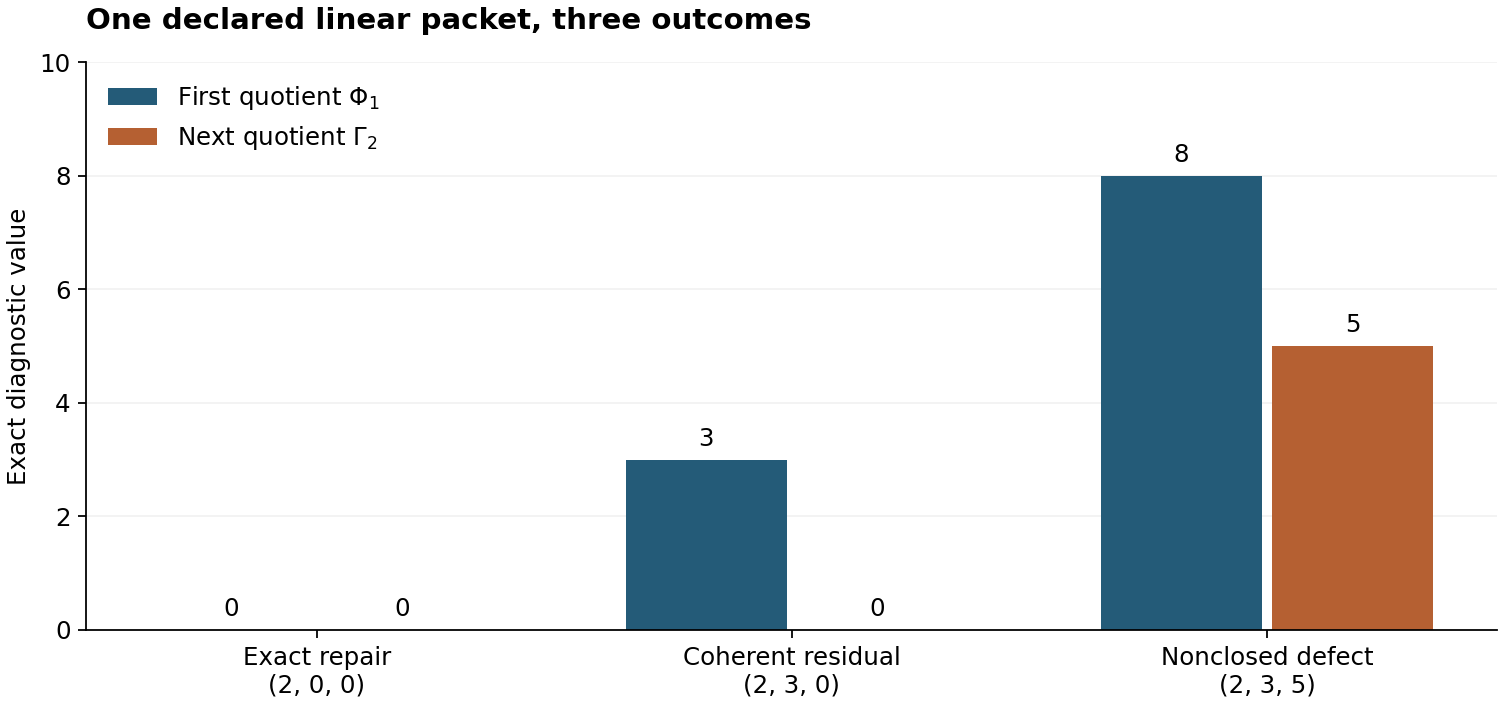

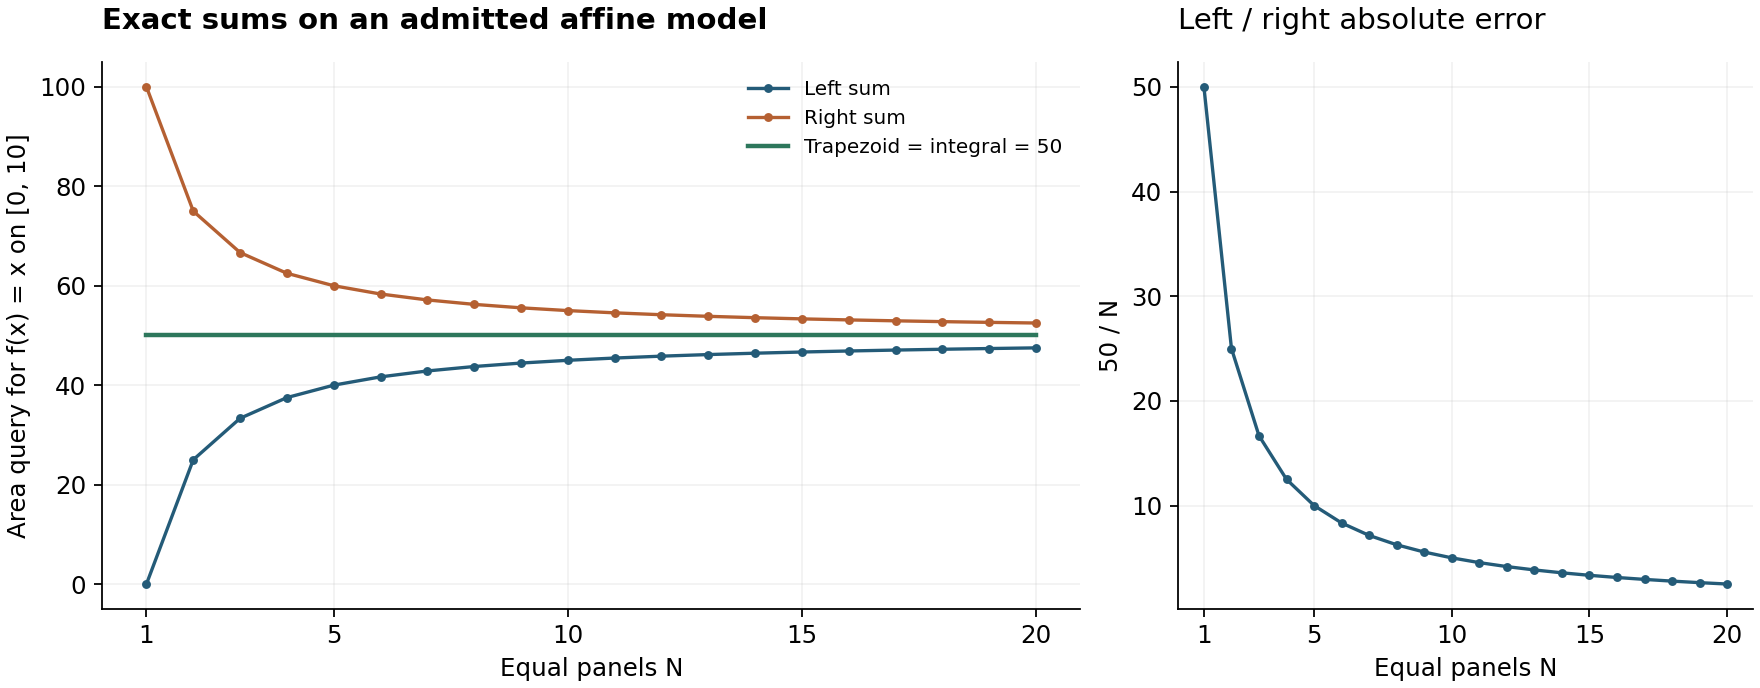

In [8]:
from IPython.display import Image, display
for name in ('coda_foc_outcomes.png', 'coda_quadrature.png'):
    display(Image(filename=str(root / 'images' / name)))